### importing libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### getting libraries

In [2]:
df=pd.read_csv("../dataset/olist_orders_dataset.csv")

In [3]:
df.head(2)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00


### inference
1) we have order_id to get individual order.
2) customer_id to get customer for individual order.
3) order_status to determine the status of order.
4) order_purchase_timestamp date time of order.
5) order_approved_at timestamp at which the order was approved
6) order_delivered_carrier_date order reached to carrier.
7) order_delivered_customer_date timestamp at which the order recieved by customer.
8) order_estimated_delivery_date estimated timestamp at which order to reach to customer.

In [4]:
df.shape

(99441, 8)

In [5]:
df.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df['order_status'][df['order_delivered_customer_date'].isnull()].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [8]:
df['order_status'][df['order_approved_at'].isnull()].value_counts()

order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [10]:
cols=['order_purchase_timestamp','order_approved_at','order_delivered_carrier_date','order_delivered_customer_date','order_estimated_delivery_date']
for i in cols:
    df[i]=pd.to_datetime(df[i])
    df[i+'_m-y']=df[i].dt.to_period('M')
    df[i]=df[i].dt.date

In [11]:
df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'order_purchase_timestamp_m-y', 'order_approved_at_m-y',
       'order_delivered_carrier_date_m-y', 'order_delivered_customer_date_m-y',
       'order_estimated_delivery_date_m-y'],
      dtype='object')

## insights`

In [12]:
df['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

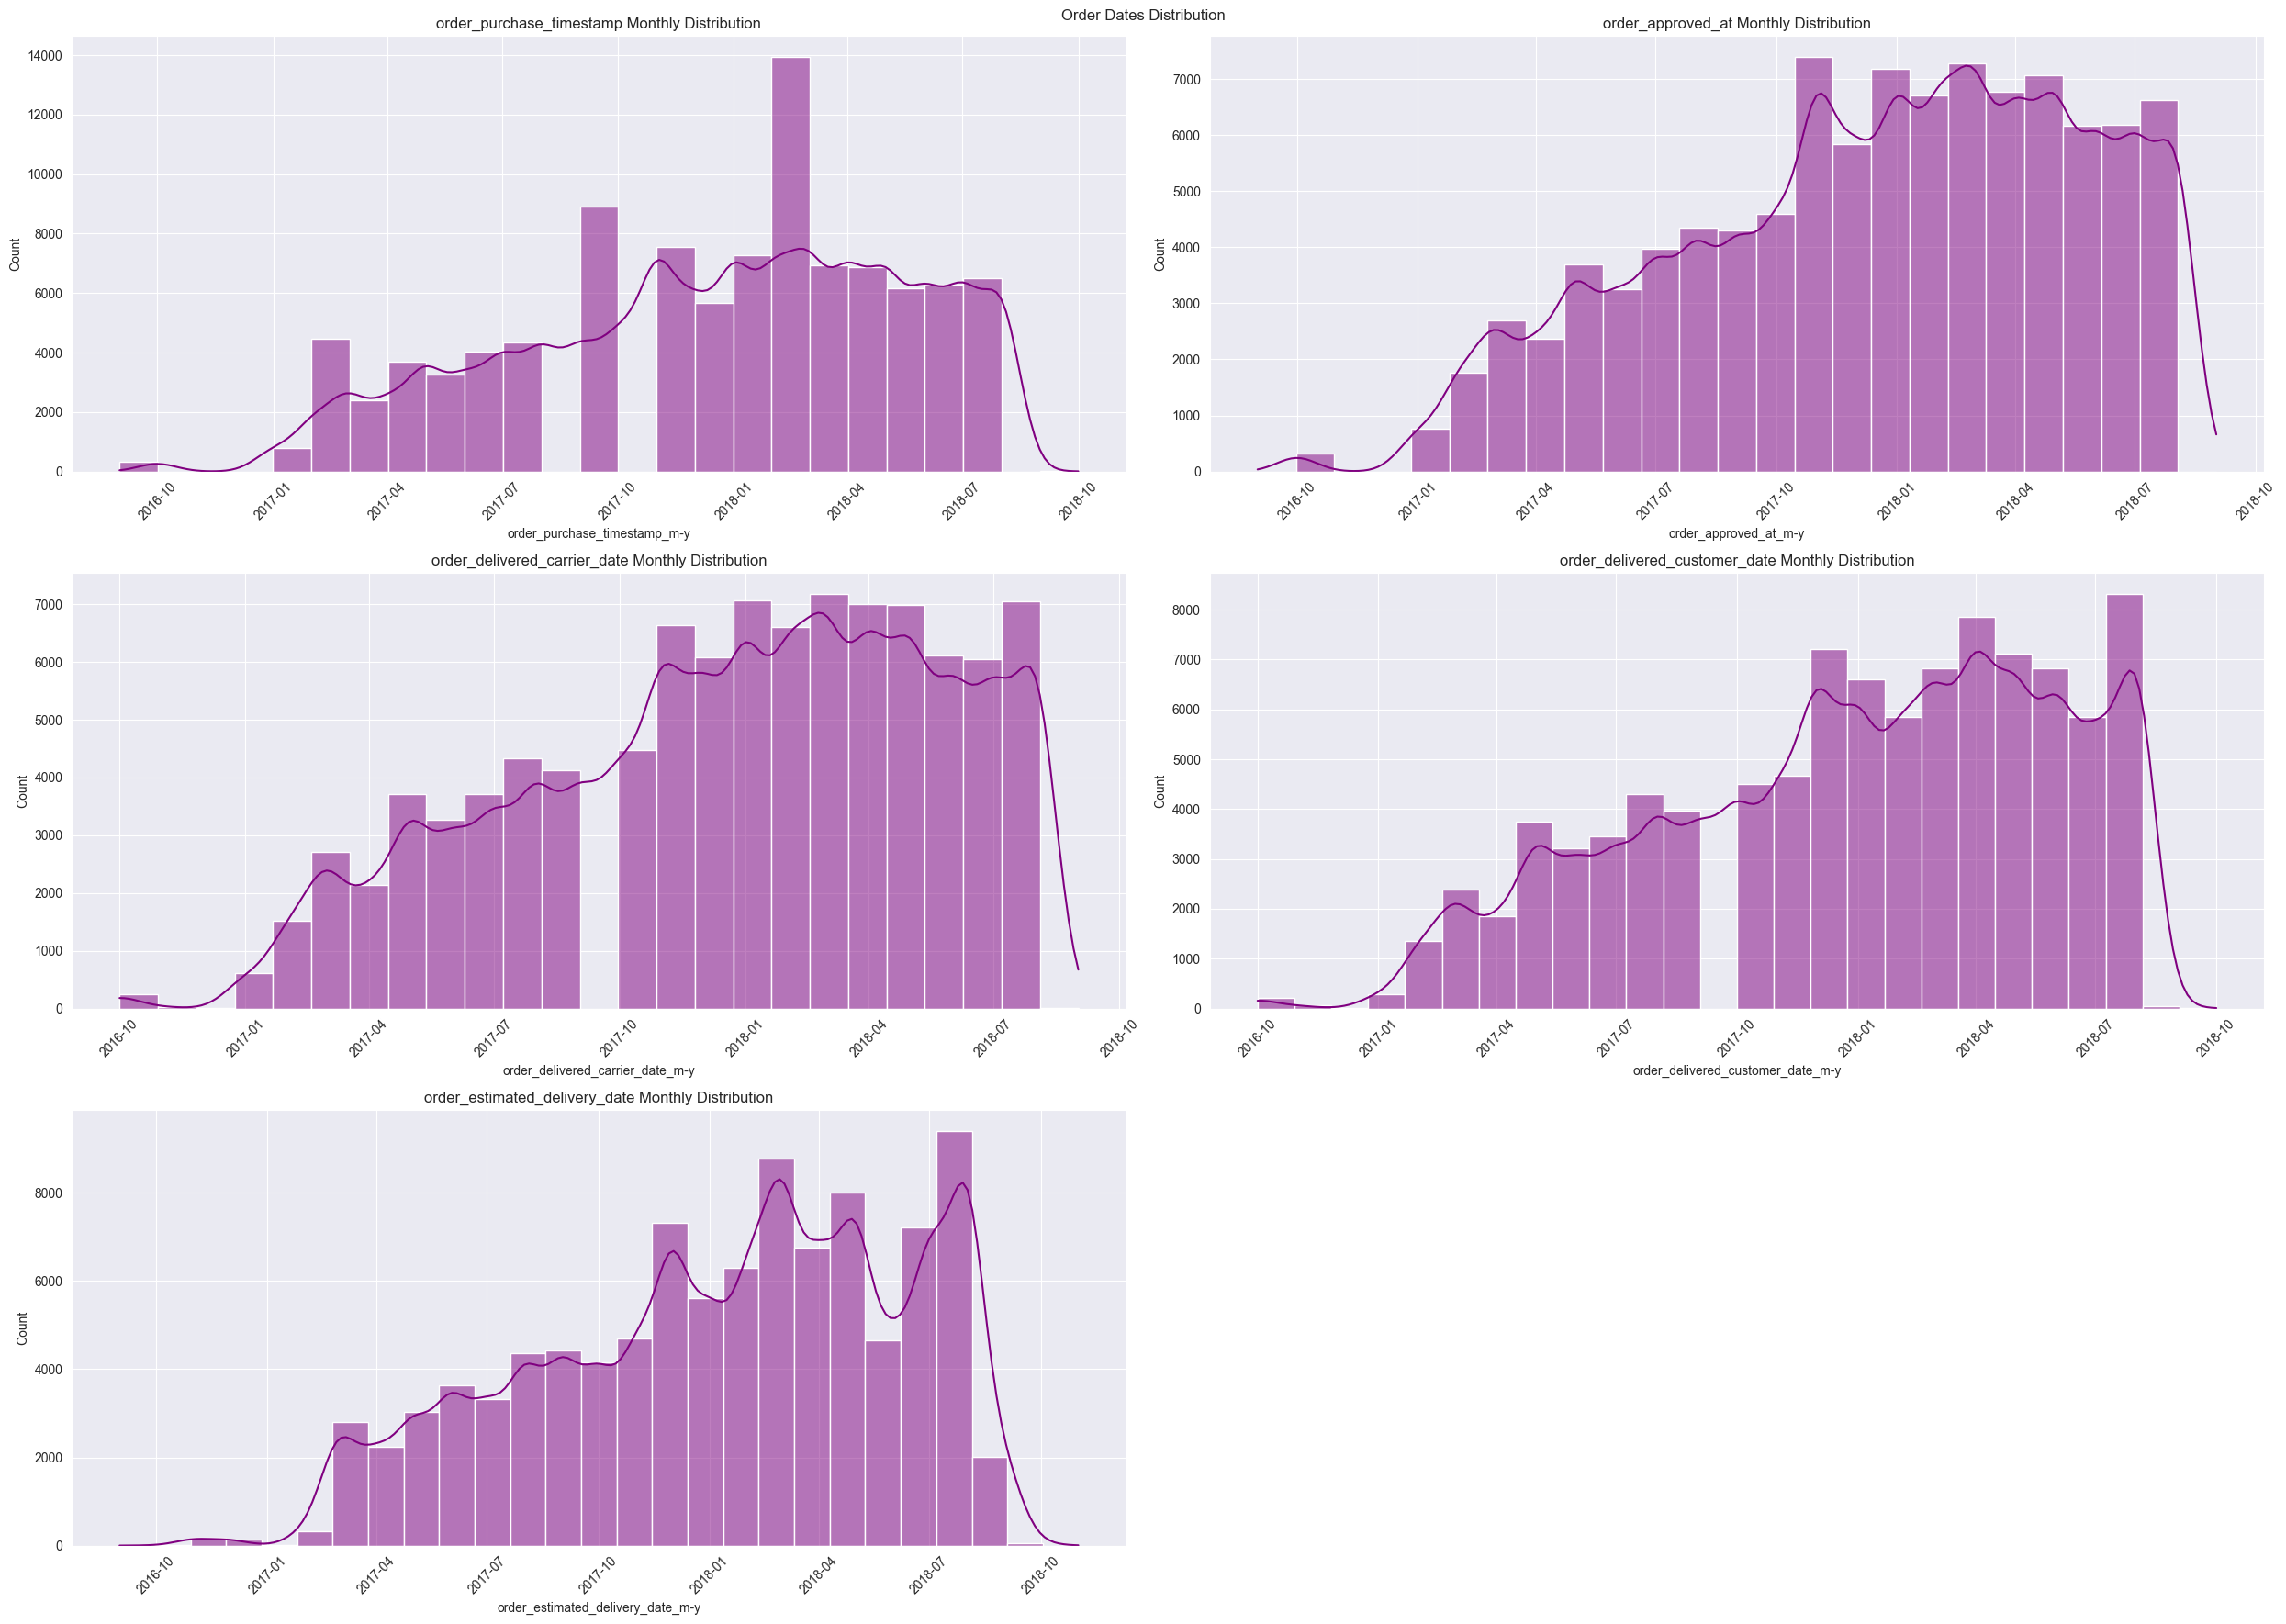

In [25]:
cols=['order_purchase_timestamp','order_approved_at','order_delivered_carrier_date','order_delivered_customer_date','order_estimated_delivery_date']
plt.figure(figsize=(25,18))
sns.set_style('darkgrid')
for i in range(len(cols)):
    plt.subplot((len(cols)+1)//2, 2, i+1)
    df[cols[i]] = pd.to_datetime(df[cols[i]])
    df[cols[i]+'_m-y'] = df[cols[i]].dt.to_period('M').dt.to_timestamp()
    sns.histplot(data=df, x=cols[i]+'_m-y', kde=True, bins=len(df[cols[i]+'_m-y'].unique()),color='purple')
    plt.title(f'{cols[i]} Monthly Distribution')
    plt.xticks(rotation=45)
    plt.tight_layout()

plt.suptitle('Order Dates Distribution')
plt.tight_layout()
plt.savefig('Orders_dates_distribution.png', dpi=500, bbox_inches="tight")
plt.show()


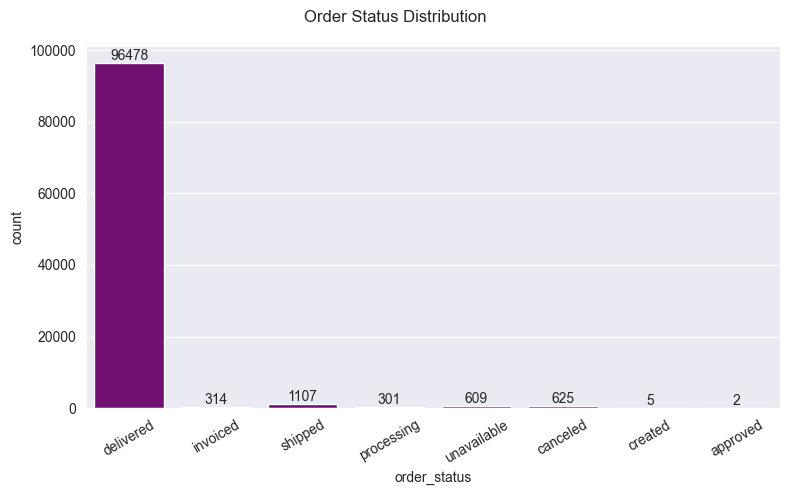

In [24]:
plt.figure(figsize=(8,5))
ax=sns.countplot(data=df,x='order_status',color='purple')
plt.bar_label(ax.containers[0])
plt.suptitle('Order Status Distribution')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('Orders_status.png', dpi=500, bbox_inches="tight")
plt.show()


## insights

In [15]:
## avg delivery time
df['delivery_time_days'] = (df['order_delivered_customer_date']-df['order_purchase_timestamp']).dt.days
x1=df['delivery_time_days'][df['order_status']=='delivered']

In [16]:
x1.mean()

np.float64(12.496848761272934)

In [17]:
## cancellation rate
tot_order=df.shape[0]
ca_order=df[df['order_status']=='canceled'].shape[0]

In [18]:
cancelation_rate=(ca_order/tot_order)*100
print(cancelation_rate)

0.6285133898492574


In [19]:
## avg Approcal time
df['approval_lag_days']=(df['order_approved_at']-df['order_purchase_timestamp']).dt.days
x2=df['approval_lag_days'][df['order_status']!='canceled']

In [20]:
x2.dropna().mean()

np.float64(0.517748514631011)

In [21]:
# avg delivery delay
df['delivery_delay_days']=(df['order_delivered_customer_date']-df['order_estimated_delivery_date']).dt.days
x3=df['delivery_delay_days'][df['delivery_delay_days']>0]

In [22]:
x3.mean()

np.float64(10.6203519510329)

In [23]:
on_time_rate = (df['delivery_delay_days'] <= 0).mean()
on_time_rate*100

np.float64(90.44659647429128)